## Pegasus Evaluation: SLO-based Composition Planning

Section C.2. Each application (audio, lidar, vision) has five compositions (A1–A5, L1–L5, V1–V5: the chains `b1u-<application>-<i>`). A client states SLOs, and a grid search over the compositions and their configurations picks the best plan that meets them (C.2a–C.2c); C.2d runs the plans on the testbed. Code: `slo_planning.py`.

**Configuration** of a composition with $K$ services: the data quality $q$ (knob `data_quality`: clip length in s, point-cloud radius in m, image height in px), the workers $w_k \in \{1, \dots, 4\}$ of service $k$ (deployed with $w_k + 0.5$ cores), and for a vision detector the model size $m_k \in \{1, 2\}$.

**SLO dimensions:** *cost*, the total workers $c = \sum_k w_k$; *latency*, the Pegasus bound on the p95 end-to-end latency at the scenario's Poisson arrival rate $\lambda$ (items/s), with violation probability $\alpha / K$ per service and $\alpha = 0.05$ (an overloaded service gives no finite bound); *quality*, $q$ (vision: also a smallest model size).

**Models:** the load-aware GPs of B.1, trained on every benchmark run with one to four workers (`C2_N_TRAIN = None`, not the `N_TRAIN` runs of B, because the deployed plans come from these models), never on a run of a chain.

In [1]:
import pandas as pd
from IPython.display import Markdown, display

import slo_planning as sp
from slo_planning import Scenario

WORKER_BUDGET = 8                  # workers; the budget of a trade-off panel in C.2c for a scenario without a worker limit
# False: keep the figures c2_slo_plans_<application> of the first deployment (statics/slo_planning/README.md)
WRITE_DEPLOYED_FILES = False

### C.2a. Scenarios

Five scenarios per application, each with a rate $\lambda$, one or two constraints, a weight per free dimension and the capabilities it requires (only compositions that have them are candidates). `configurations`: the grid size over the candidates. *Typical value* of a dimension: its median over the candidates' configurations that meet the constraints (`typical_scales`). The objective divides every dimension by its typical value, so a weight prices a relative change: with weights 1 (quality) and 0.5 (latency), 10 % more quality is worth 20 % more latency.

In [2]:
# Scenario(name, arrival rate in items/s, weights of the free dimensions, constraints, requires=capabilities, note=client)
SCENARIOS = {
    "audio": [
        Scenario("S-A-1 shared gateway", 6.0, dict(latency=0.5, quality=1.0), max_workers=4, requires=("noise suppression",),
                 note="noise suppression of 6 clips per second on a gateway that grants the pipeline 4 cores"),
        Scenario("S-A-2 voice assistant", 6.0, dict(cost=1.0, quality=0.2), max_latency=0.050, requires=("voice activity",),
                 note="a voice assistant that detects speech in 6 clips per second and must respond without a noticeable pause"),
        Scenario("S-A-3 music archive", 3.0, dict(cost=1.0, latency=0.1), min_quality=10, requires=("audio encoding",),
                 note="recordings encoded for an archive in clips of 10 s or more; latency matters little"),
        Scenario("S-A-4 call analytics", 6.0, dict(latency=1.0), max_workers=6, min_quality=6, requires=("voice activity",),
                 note="speech detection in recorded calls, 6 clips per second in clips of 6 s or more, on 6 cores; results as fast as possible"),
        Scenario("S-A-5 conferencing", 6.0, dict(cost=1.0, quality=0.5), max_latency=0.150, requires=("noise suppression",),
                 note="a conference call with noise suppression within the 150 ms mouth-to-ear budget of ITU-T G.114"),
    ],
    "lidar": [
        Scenario("S-L-1 delivery robot", 12.0, dict(latency=1.0, quality=1.0), max_workers=6, requires=("clustering",),
                 note="obstacle clusters from a 12 Hz lidar on the embedded computer of a delivery robot with 6 cores"),
        Scenario("S-L-2 collision avoidance", 12.0, dict(cost=1.0, quality=1.0), max_latency=0.080, requires=("ground removal",),
                 note="obstacles above the ground must be known before the next scan of a 12 Hz lidar (80 ms)"),
        Scenario("S-L-3 HD mapping", 12.0, dict(cost=1.0, latency=0.1), min_quality=30, requires=("registration",),
                 note="offline map building from registered scans with a radius of 30 m or more; latency matters little"),
        Scenario("S-L-4 fleet perception", 15.0, dict(cost=1.0, quality=0.5), max_latency=0.250, requires=("normal estimation",),
                 note="surface normals for a fleet of slow vehicles, results within 250 ms"),
        Scenario("S-L-5 robotaxi", 20.0, dict(quality=1.0), max_workers=10, max_latency=0.200, requires=("point cloud encoding",),
                 note="a 10-core perception box that streams the encoded cloud of a 20 Hz lidar to remote operators within 200 ms"),
    ],
    "vision": [
        Scenario("S-V-1 edge box", 15.0, dict(latency=0.5, quality=1.0), max_workers=6, requires=("object detection",),
                 note="a 15 fps camera with an edge box that has 6 cores for the pipeline; detects objects"),
        Scenario("S-V-2 interactive AR", 30.0, dict(cost=1.0, quality=0.5), max_latency=0.100, requires=("face detection",),
                 note="an augmented-reality face filter at 30 fps that must follow the scene within three frames"),
        Scenario("S-V-3 forensic detail", 12.0, dict(cost=1.0, latency=0.1), min_quality=512, min_model=2, requires=("object detection",),
                 note="incident review of a 12 fps camera: objects at 512 px or more with the larger model; latency matters little"),
        Scenario("S-V-4 retail analytics", 15.0, dict(cost=1.0, quality=0.5), max_latency=0.250, requires=("QR codes",),
                 note="a store camera at 15 fps that reads product codes within 250 ms"),
        Scenario("S-V-5 traffic monitoring", 25.0, dict(latency=1.0, quality=1.0), max_workers=10, requires=("motion detection",),
                 note="a roadside unit with 10 cores that detects moving vehicles in a 25 fps stream"),
    ],
}

In [3]:
# compositions[scenario name]: the five compositions of the application with the node bounds of every service on its
# knob grid at the arrival rate of the scenario (scenarios with the same application and rate share the tables)
tables = {}
compositions = {s.name: [tables.setdefault((e, s.rate), sp.composition(e, s.rate)) for e in sp.APPLICATIONS[app]]
                for app, scenarios in SCENARIOS.items() for s in scenarios}
# scales[scenario name]: the typical cost, latency and quality of the scenario, which normalize the objective
scales = {s.name: sp.typical_scales(compositions[s.name], s) for scenarios in SCENARIOS.values() for s in scenarios}
# candidates[scenario name]: the compositions with every required capability
candidates = {s.name: [c for c in compositions[s.name] if sp.provides(c, s.requires)] for scenarios in SCENARIOS.values() for s in scenarios}
display(pd.DataFrame([dict(application=app, scenario=s.name, rate=s.rate, constraints=s.constraints(), objective=s.goal(),
                           requires=", ".join(s.requires), candidates=", ".join(c.label for c in candidates[s.name]),
                           configurations=sum(len(sp.all_grid_indices(c)) for c in candidates[s.name]),   # grid size over all candidates
                           typical_workers=scales[s.name].cost, typical_p95_ms=1e3 * scales[s.name].latency, typical_quality=scales[s.name].quality)
                      for app, scenarios in SCENARIOS.items() for s in scenarios]).set_index(["application", "scenario"])
        .style.format(dict(rate="{:g}", configurations="{:,}", typical_workers="{:g}", typical_p95_ms="{:.0f}", typical_quality="{:g}")))
# services whose training runs never had the scenario's rate: their GPs extrapolate the load input
extrapolated = [f"{s.name}, {c.label}: {', '.join(c.extrapolated)}" for scenarios in SCENARIOS.values() for s in scenarios
                for c in candidates[s.name] if c.extrapolated]
if extrapolated:
    display(Markdown("Rate outside the training runs of a service (extrapolated): " + "; ".join(extrapolated)))

C:\Users\boris\development\composable-autonomous-offerings\venv\Lib\site-packages\numpy\_core\fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\boris\development\composable-autonomous-offerings\venv\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Rate outside the training runs of a service (extrapolated): S-A-1 shared gateway, A1: resampler, features; S-A-1 shared gateway, A2: encoder; S-A-2 voice assistant, A2: encoder; S-A-2 voice assistant, A3: resampler, encoder; S-A-3 music archive, A2: voice, encoder; S-A-3 music archive, A3: resampler, voice, pitch, encoder; S-A-3 music archive, A5: resampler, pitch, features, encoder; S-A-4 call analytics, A2: encoder; S-A-4 call analytics, A3: resampler, encoder; S-A-5 conferencing, A1: resampler, features; S-A-5 conferencing, A2: encoder; S-L-1 delivery robot, L4: viewer; S-L-2 collision avoidance, L4: viewer; S-L-3 HD mapping, L3: viewer; S-L-5 robotaxi, L4: viewer; S-V-1 edge box, V1: compressor; S-V-1 edge box, V3: compressor; S-V-1 edge box, V5: motion, compressor; S-V-2 interactive AR, V3: compressor; S-V-2 interactive AR, V5: compressor; S-V-3 forensic detail, V1: compressor; S-V-3 forensic detail, V3: compressor; S-V-3 forensic detail, V5: motion, edges, compressor; S-V-4 retail analytics, V4: motion; S-V-4 retail analytics, V5: motion, compressor; S-V-5 traffic monitoring, V5: compressor

### C.2b. Grid Search

The end-to-end bound is a sum of node bounds that each depend only on the knobs of their own service, so every configuration of every candidate is evaluated from table entries. The plan minimizes the weighted sum of the free dimensions, each divided by its typical value, plus `TIE_WEIGHT` times each constrained one, among the configurations that meet the constraints. The SLSQP solver of the RASK paper remains in `slo_planning.py` (`solver="slsqp"`) but is not run.

In [4]:
plans = {(app, scenario.name): sp.plan(compositions[scenario.name], scenario, scales[scenario.name])
         for app, scenarios in SCENARIOS.items() for scenario in scenarios}

### C.2c. Inferred Configurations

Predicted bounds only; C.2d compares the plans with measurements.

**Trade-off per scenario.** One panel per scenario. x axis: data quality $q$. y axis (log): per candidate composition, the smallest predicted p95 bound (ms) over its configurations with at most $c$ workers, the total of the plan (for a best-effort plan the scenario's worker limit, or `WORKER_BUDGET`). A line ends where every configuration overloads a service; it is dashed with hollow markers where $q$ lies outside the training runs of a service (the GP extrapolates). Dashed black lines: the latency limit and the smallest quality; red zone: an SLO is violated. Star: the plan, labeled with $c$ (hollow: best effort).

audio


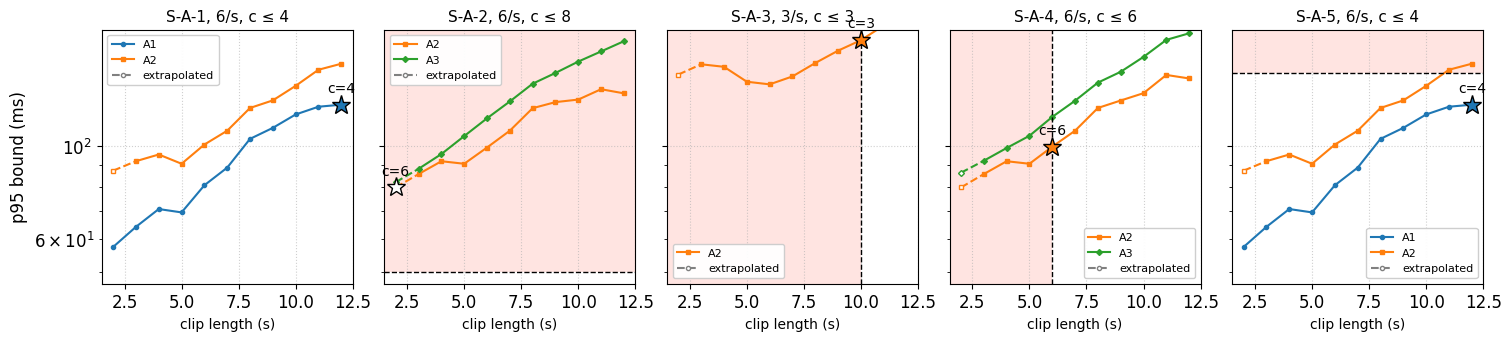

lidar


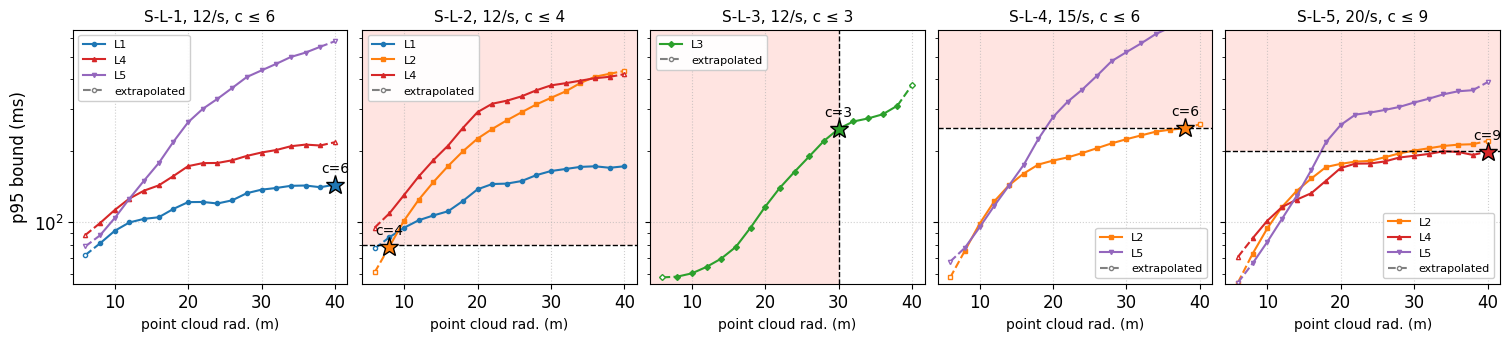

vision


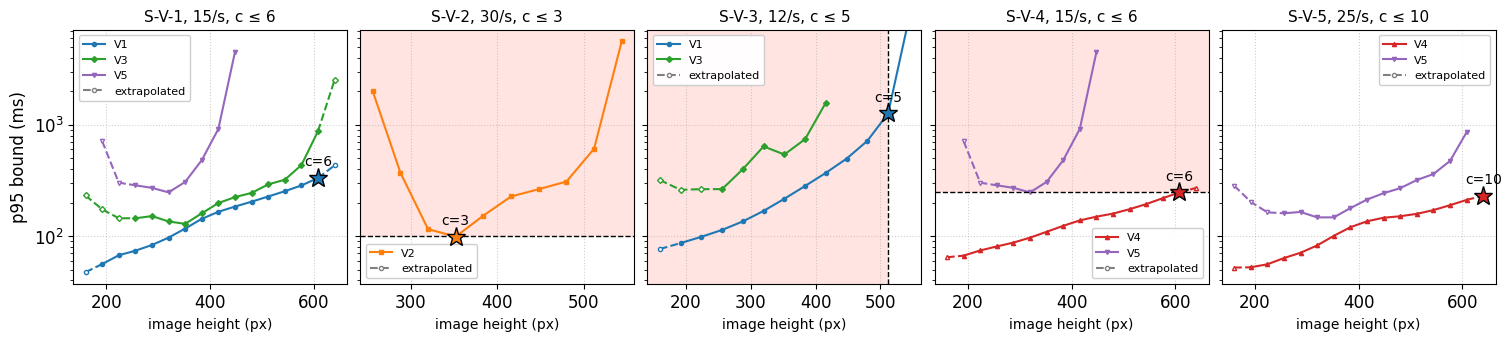

In [5]:
for app, scenarios in SCENARIOS.items():
    print(app)   # above the figure, not in it (no title in a paper figure)
    sp.tradeoff_figure({s.name: compositions[s.name] for s in scenarios}, plans, scenarios, app, WORKER_BUDGET,
                       name=f"c2_slo_plans_{app}" if WRITE_DEPLOYED_FILES else None)

**Configurations to deploy.** The cell below writes the plans in the knob names of the campaign (`<node>.cores` $= w_k + 0.5$), with rate and predicted bound, to `statics/slo_planning/c2_plans_new.csv`. If no configuration meets the SLOs, the plan is *best effort*: the smallest predicted bound among the configurations that meet the other constraints (`best_effort` True, hollow star). The deployed plans are frozen in `c2_plans_v2.csv` (`DEPLOYED_PLANS`, written by this cell on 2026-11-14); those of the first deployment, from older models, are in `c2_plans_old.csv` (`statics/slo_planning/README.md`).

In [6]:
# the plans above in the knob names of the campaign, to deploy them; a scenario that no configuration meets gets its best-effort
# configuration (best_effort True). Not DEPLOYED_PLANS (c2_plans_v2.csv): that file holds the deployed plans, which C.2d reads.
deployment = sp.deployment_table(plans, {s.name: s.rate for scenarios in SCENARIOS.values() for s in scenarios})
sp.PLANS.mkdir(parents=True, exist_ok=True)
deployment.to_csv(sp.PLANS / "c2_plans_new.csv", index=False)

### C.2d. Deployment on the Testbed

The plans of `DEPLOYED_PLANS` ran on the testbed at the rate of their scenario (`C2_RESULTS`: `statics/results_milos_v2/c2/v2/`; the first deployment is in `c2/v1/`). The unit is the request: the end-to-end latency (ms) of every completed request, pooled over the runs of a scenario.

**Table.** `best_effort`: see C.2c. `as_planned`: the deployed knobs and rate are those of the plan. `bound_ms`: the predicted p95 bound of the plan. `measured_p95_ms`, `measured_p99_ms`: percentiles of the pooled requests. `above_bound_pct`: the share of requests slower than the bound (a p95 bound allows 5 %). `tightness` = `bound_ms / measured_p95_ms` (1 is exact, larger is looser). `slo_ms`: the latency SLO, if any.

In [7]:
# the deployed plans (sp.DEPLOYED_PLANS) and the requests of their testbed runs (sp.C2_RESULTS), feasible and best-effort plans
deployed = pd.read_csv(sp.DEPLOYED_PLANS)
scenario_by_name = {s.name: s for scenarios in SCENARIOS.values() for s in scenarios}
measured = sp.measured_c2(deployed)
display(sp.testbed_table(deployed, measured, scenario_by_name).set_index(["application", "scenario"])
        .style.format(dict(requests="{:,}", bound_ms="{:.0f}", measured_p95_ms="{:.0f}", measured_p99_ms="{:.0f}",
                           above_bound_pct="{:.2f}", tightness="{:.2f}", slo_ms="{:.0f}"), na_rep="–"))

**Figure (alternative to the table).** Per scenario, the share of requests slower than $x$ (blue, log axis) against the latency $x$ (ms). The curve crosses the dotted line at 0.05 at the measured p95; the bound (red) holds if it lies right of that crossing, and the gap is its looseness. Dashed: the latency SLO.

audio


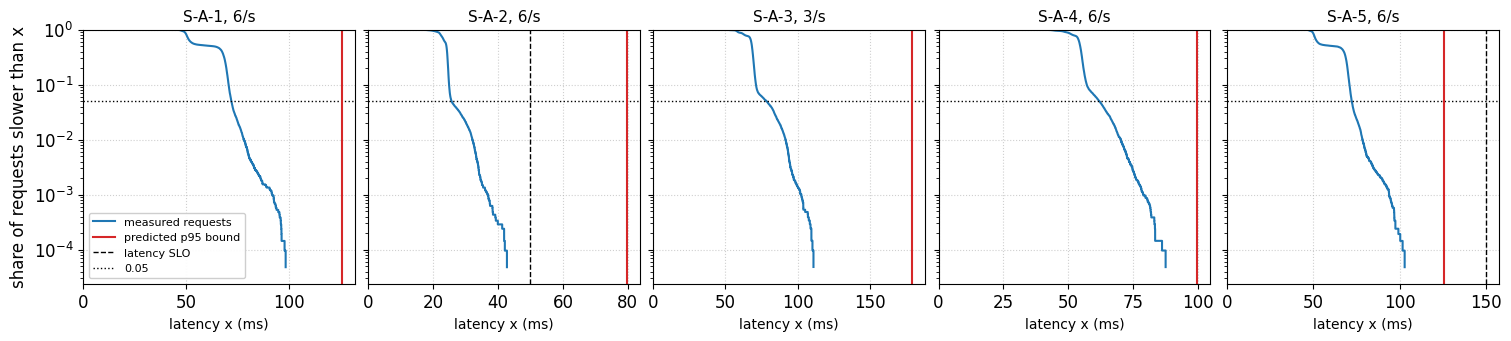

lidar


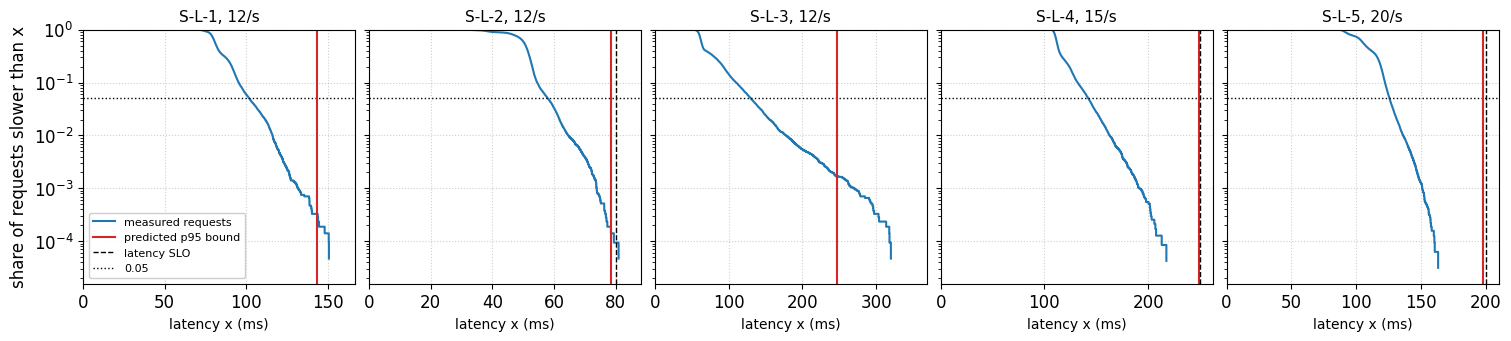

vision


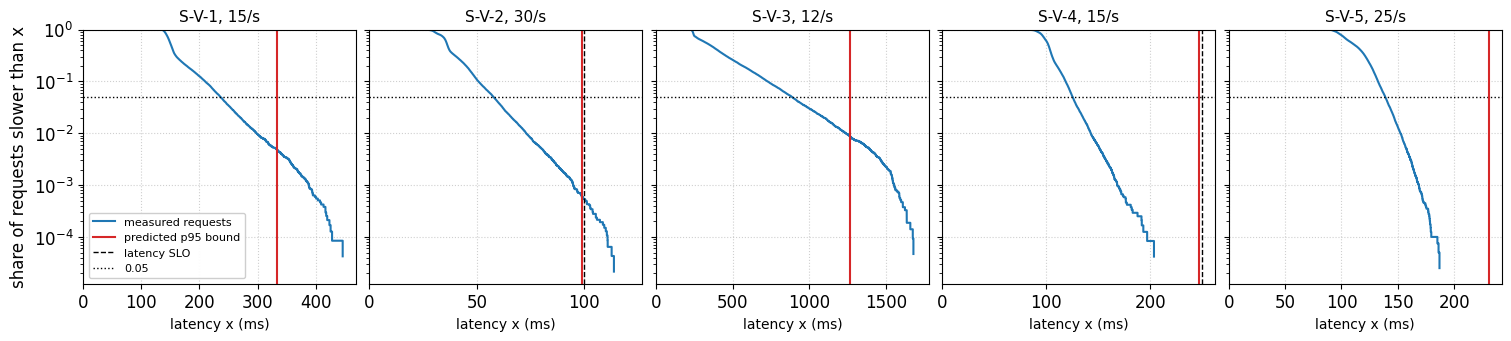

In [8]:
for app, scenarios in SCENARIOS.items():
    print(app)   # above the figure, not in it (no title in a paper figure)
    sp.testbed_figure(measured, deployed, scenarios, app)   # name=...: not exported until you pick table or figure

**Every scenario as a candidate panel.** Each scenario as the third-width panel of the selected figures below, to choose from (shown, not saved). A panel is the trade-off of C.2c plus the measured requests of the deployed plan at its $q$: a box from the 25th to the 75th percentile with the median, whiskers to the last request within 1.5 interquartile ranges (requests beyond them are not drawn but count in the p95), and a magenta bar at the 95th percentile. Where the deployed configuration is not the plan, a hollow diamond marks the bound that the models give it. The bound holds where the star lies above the magenta bar; the vertical gap is its looseness.


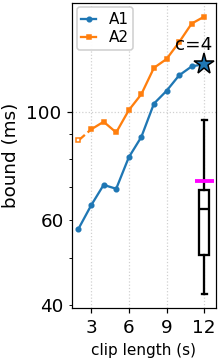
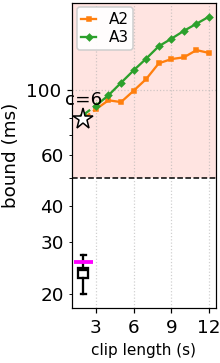
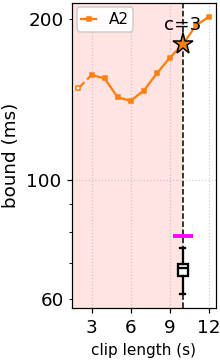
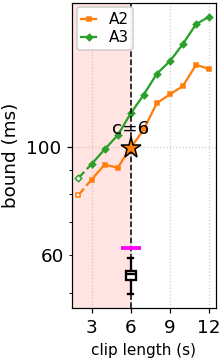
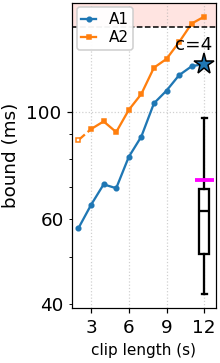


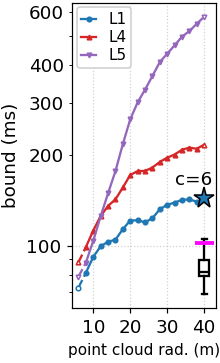
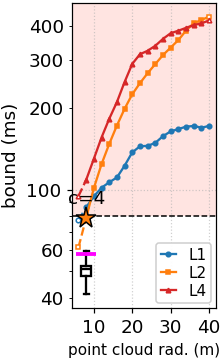
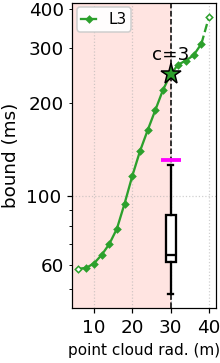
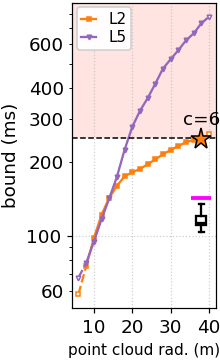
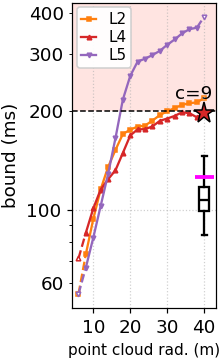


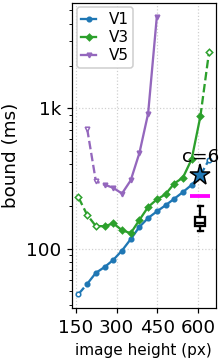
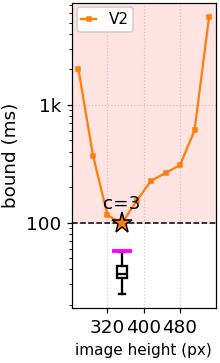
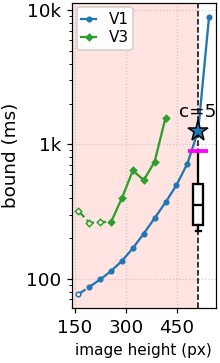
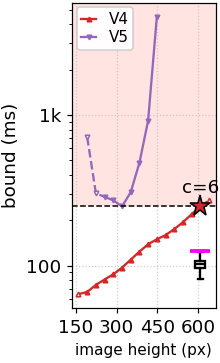
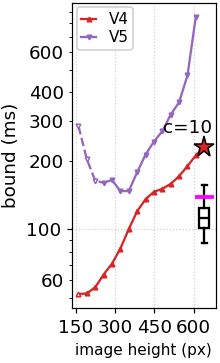

In [9]:
# every scenario as a third-width panel, to choose SELECTED below (nothing is saved)
sp.tradeoff_third_overview(SCENARIOS, compositions, plans, WORKER_BUDGET, measured, deployed)

**Selected panels** (`SELECTED`, one per application), saved as `c2_tradeoff_<scenario>`: three files of the same size, a third of the width of an evaluation figure, with the same plot area, so that they stand side by side in the paper. Only the first names the y axis (predicted p95 bound, ms, log). The panels show the three kinds of SLO: audio (S-A-1) only a worker limit, lidar (S-L-5) a latency limit, vision (S-V-3) a quality limit. The legends share out the symbols: audio explains the star (labeled with its workers $c$), lidar the SLO limit, vision the box plot of the measured requests and its p95 bar. The printed line checks that each star is the bound of the deployed configuration.

S-A-1 shared gateway: star 125.7 ms, deployed configuration 125.7 ms
S-L-5 robotaxi: star 198.1 ms, deployed configuration 198.1 ms
S-V-3 forensic detail: star 1265.2 ms, deployed configuration 1265.2 ms


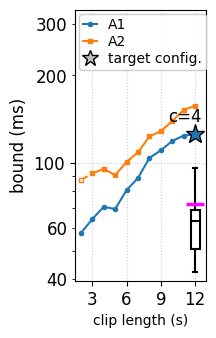

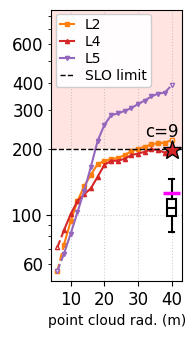

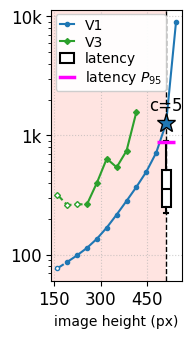

In [10]:
# in the order of the figures, left to right; plan = deployed configuration (almost)
SELECTED = {"audio": "S-A-1 shared gateway", "lidar": "S-L-5 robotaxi", "vision": "S-V-3 forensic detail"}
for app, name in SELECTED.items():
    star = plans[(app, name)].iloc[0]["latency_ms"]
    diamond = sp._measurement(scenario_by_name[name], compositions[name], measured, deployed)[1]   # current-model bound of the deployed configuration
    print(f"{name}: star {star:.1f} ms, deployed configuration {diamond:.1f} ms")   # printed above the figures, not in them
# the legends also describe the symbols of all three figures (sp._panel_notes), split between the figures: all four entries in one legend
# are wider than a plot
sp.tradeoff_third_figures(SELECTED, compositions, plans, scenario_by_name, WORKER_BUDGET, measured, deployed,
                          notes={"audio": ["plan"], "lidar": ["slo"], "vision": ["box", "bar"]})